In [4]:
# imports
import numpy as np
#feature extraction from the image
## importing the necessary modules for feature extraction 
import torch
import torch.nn as nn
from torchvision import transforms, datasets
from torch.utils.data import Dataset, DataLoader
from linformer import Linformer 
from itertools import chain   
from vit_pytorch.efficient import ViT   
data = {}

#data['test']  = np.load('drive/MyDrive/dataverse_files/Dataset5_raw_test.npz')
data['train'] = dict(np.load('dataverse_files/Dataset5_raw_train.npz'))
data['val']   = dict(np.load('dataverse_files/Dataset5_raw_val.npz'))

In [2]:
!pip install linformer
!pip install vit_pytorch

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


In [5]:
# normalize image data
# N x 224 x 224 x3 
# take avg of N images

mean = data['train']['image'].mean(axis=(0,1,2), keepdims=True)
devia = data['train']['image'].std(axis=(0,1,2), keepdims=True)
data['train']['image'] = (data['train']['image'] - mean) / devia
data['val']['image'] = (data['val']['image'] - mean) / devia

In [6]:
class CustomDataset(Dataset):
    def __init__(self, data, labels, transform):
        self.transform = transform
        self.data = data
        self.labels = labels
    
    def __len__(self):
        return self.labels.size

    def __getitem__(self, idx):
        temp = int(self.labels[idx])
            
        return self.transform(self.data[idx]).float(), temp

In [7]:
transform = transforms.Compose([transforms.ToTensor()])
print(data['train']['image'].transpose(0, 3, 1, 2).shape)
trainset = CustomDataset(data['train']['image'], data['train']['image_label'], transform)
train_loader = DataLoader(trainset, 64, shuffle=True, drop_last=True)

(19610, 3, 224, 224)


In [8]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

efficient_transformer = Linformer(
    dim=128,
    seq_len=49+1,  # 7x7 patches + 1 cls-token
    depth=12,
    heads=8,
    k=64
)

model = ViT(
    dim=128,
    image_size=224,
    patch_size=32,
    num_classes=100,
    transformer=efficient_transformer,
    channels=3
).to(device)

model.load_state_dict(torch.load("vit_fext_71.pth"))
model.eval()

ViT(
  (to_patch_embedding): Sequential(
    (0): Rearrange('b c (h p1) (w p2) -> b (h w) (p1 p2 c)', p1=32, p2=32)
    (1): LayerNorm((3072,), eps=1e-05, elementwise_affine=True)
    (2): Linear(in_features=3072, out_features=128, bias=True)
    (3): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
  )
  (transformer): Linformer(
    (net): SequentialSequence(
      (layers): ModuleList(
        (0-11): 12 x ModuleList(
          (0): PreNorm(
            (fn): LinformerSelfAttention(
              (to_q): Linear(in_features=128, out_features=128, bias=False)
              (to_k): Linear(in_features=128, out_features=128, bias=False)
              (to_v): Linear(in_features=128, out_features=128, bias=False)
              (dropout): Dropout(p=0.0, inplace=False)
              (to_out): Linear(in_features=128, out_features=128, bias=True)
            )
            (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
          )
          (1): PreNorm(
            (fn): Fe

In [11]:
y_pred = []
y_train = []
for x, y in train_loader:
    y_pred = y_pred + model(torch.tensor(x).to(device)).cpu().detach().numpy().tolist()
    y_train = y_train + y.detach().numpy().tolist()
    
print(len(y_pred))
print(len(y_train))

<ipython-input-11-66dea90b81bf>:4: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = y_pred + model(torch.tensor(x).to(device)).cpu().detach().numpy().tolist()


19584
19584


In [12]:
print(data['val']['image'].transpose(0, 3, 1, 2).shape)

valset = CustomDataset(data['val']['image'], data['val']['image_label'], transform)
val_loader = DataLoader(valset, 1, shuffle=True)

(6534, 3, 224, 224)


In [15]:
y_pred_val = []
y_val = []
for x, y in val_loader:
    y_pred_val.append(model(torch.tensor(x).to(device)).cpu().detach().numpy())
    y_val.append(y.detach().numpy()[0])
    
print(len(y_pred_val))
print(y_pred_val[1].shape)
print(len(y_val))

<ipython-input-15-804ab34c8b37>:4: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred_val.append(model(torch.tensor(x).to(device)).cpu().detach().numpy())


6534
(1, 100)
6534


In [16]:
def relu(Z):
    return Z*(Z>0)

def relu_backward(Z):
    return 1* (Z>0)

def softmax(Z):
    return np.exp(Z) / np.sum(np.exp(Z), axis = 1, keepdims=True)

class FCN():

    def __init__(self, dims, activation, lr, momentum, initialization, weight_decay, unif_decay):
        self.unif_decay = unif_decay
        self.dims = dims
        self.activation = activation
        self.lr = lr
        self.momentum = momentum
        self.weight_decay = weight_decay

        self.weights  = {}
        self.bias = {}
        self.deltaW = {}
        self.v = {}

        for i in range(len(dims)-1):
            self.deltaW['L'+str(i+1)] = 0
            self.deltaW['b'+str(i+1)] = 0
            self.v['L'+str(i+1)] = np.zeros(shape=(dims[i+1], dims[i]))
            self.v['b'+str(i+1)] = np.zeros(shape=(1, dims[i+1]))

            self.weights['L'+str(i+1)] = np.random.normal(0, 0.0001, (dims[i+1], dims[i]))
            self.bias['L'+str(i+1)]    = np.random.normal(0, 0.0001, (dims[i+1], 1))

        
    def forward_pass(self, input):
        self.out = {}
        self.out['L0'] = input
        self.out['F0'] = input
        L = len(self.dims)-1

        for i in range(L-1):         
            #print(self.weights['L'+str(i+1)].shape, '     ', self.out['L'+str(i)].shape  )
            #print(self.bias['L'+str(i+1)].shape)
            self.out['L'+str(i+1)] = self.out['L'+str(i)] @ self.weights['L'+str(i+1)].T
            self.out['L'+str(i+1)] = self.out['L'+str(i+1)] + self.bias['L'+str(i+1)].T
            self.out['F'+str(i+1)] = relu(self.out['L'+str(i+1)])

        self.out['L'+str(L)] = self.out['L'+str(L-1)] @ self.weights['L'+str(L)].T 
        self.out['L'+str(L)] = self.out['L'+str(L)] + self.bias['L'+str(L)].T
        self.out['F'+str(L)] = softmax(self.out['L'+str(L)])
        
        return self.out['F'+str(L)]

    
    # considering E to be of the form NxO
    def back_pass(self, err):
        L = len(self.dims) - 1
        dW = {}

        dW['L'+str(L)] = err.T  @ self.out['F'+str(L-1)]
        dW['b'+str(L)] = np.sum(err, axis=0, keepdims=True)
        err = ( err @ self.weights['L'+str(L)]) * relu_backward(self.out['L'+str(L-1)])

        
        self.deltaW['L'+str(L)] = (self.momentum * self.deltaW['L'+str(L)]) + ((1 - self.momentum)* dW['L'+str(L)])
        self.deltaW['b'+str(L)] = (self.momentum * self.deltaW['b'+str(L)]) + ((1 - self.momentum)* dW['b'+str(L)])
        
        #print("depte ---", np.square(dW['L'+str(L)]).shape)
        
        self.v['L'+str(L)] = (self.unif_decay * self.v['L'+str(L)]) + ((1 - self.unif_decay)* np.square(dW['L'+str(L)]))
        #print("zeplin ---", self.v['b'+str(L)].shape)
        self.v['b'+str(L)] = (self.unif_decay * self.v['b'+str(L)]) + ((1 - self.unif_decay)* np.square(dW['b'+str(L)]))
        #print("zeplin ---", self.v['b'+str(L)].shape)
        for i in range(L-1):
            dW['L'+str(L-1-i)] = err.T  @ self.out['F'+str(L-2-i)]
            dW['b'+str(L-1-i)] = np.sum(err, axis=0, keepdims=True)
            err = ( err @ self.weights['L'+str(L-1-i)]) * relu_backward(self.out['L'+str(L-2-i)])

            self.deltaW['L'+str(L-1-i)] = (self.momentum * self.deltaW['L'+str(L-1-i)]) + ((1 - self.momentum)* dW['L'+str(L-1-i)])
            self.deltaW['b'+str(L-1-i)] = (self.momentum * self.deltaW['b'+str(L-1-i)]) + ((1 - self.momentum)* dW['b'+str(L-1-i)])

            #print("depte ---", np.square(dW['L'+str(L-1-i)]).shape)
            #print("zeplin ---", self.v['b'+str(L-i-1)].shape)
            self.v['L'+str(L-1-i)] = (self.unif_decay * self.v['L'+str(L-1-i)]) + ((1 - self.unif_decay)* np.square(dW['L'+str(L-1-i)]))            
            self.v['b'+str(L-1-i)] = (self.unif_decay * self.v['b'+str(L-1-i)]) + ((1 - self.unif_decay)* np.square(dW['b'+str(L-1-i)]))
            #print("zeplin ---", self.v['b'+str(L-i-1)].shape)

    def update_weights(self):
        L = len(self.dims) - 1
      
        for i in range(L):
            #print(self.v['L'+str(i+1)].shape)
            self.weights['L'+str(i+1)] = self.weights['L'+str(i+1)] + ((self.lr * (self.deltaW['L'+str(i+1)]) * (1 - self.unif_decay)) / ((1-self.momentum)*(np.sqrt(self.v['L'+str(i+1)]) +1e-15)*(1 - self.momentum)))
            #print(self.weights['L'+str(i+1)].shape)
            #print(self.v['L'+str(i+1)].shape)
            self.bias['L'+str(i+1)] = self.bias['L'+str(i+1)] + ((self.lr * (self.deltaW['b'+str(i+1)].T) * (1 - self.unif_decay)) / ((1-self.momentum)*(np.sqrt(self.v['b'+str(i+1)]).T +1e-15)*(1 - self.momentum)))
            

    def cache_bestweights(self):
        self.best = {}
        self.best['w'] = self.weights
        self.best['b'] = self.bias

In [17]:
y_true = np.zeros(shape=(len(y_train), 5))
for i in range(len(y_train)):
    y_true[i, y_train[i]] = 1

y_true.shape

(19584, 5)

In [18]:
y_true_val = np.zeros(shape=(len(y_val), 5))
for i in range(len(y_val)):
    y_true_val[i, y_val[i]] = 1

print(y_true_val.shape)

(6534, 5)


In [19]:
def cross_entropy_loss(AL, Y):
    m = Y.shape[0]
    cost = -1 * np.sum(np.multiply( np.log(AL), Y) + np.multiply( np.log(1 - AL), 1 - Y)) / m
    cost = np.squeeze(cost)

    return cost

y_net = np.reshape(np.array(y_pred),(-1,100))
y_net_val = np.array(y_pred_val).reshape(-1,100)
### normalize the outputs from the feature extractor

mlp   = FCN([100, 50, 5], None, 0.00000001, 0.9, None, 0, 0.9)

accuracy = []
val_errors = []
train_errors = []
max = 0
## training loop
batch_size = 1
iterations = int(y_net.shape[0] / batch_size)
val_iter   = y_net_val.shape[0]

for i in range(100):
    print('Epoch:' + str(i+1))
    train_error = 0
    val_error = 0
    val_correct = 0

    # batch size = 16
    for j in range(iterations):
        out = mlp.forward_pass(y_net[j*batch_size: j*batch_size+batch_size,])
        #print(out)
        train_error += cross_entropy_loss(out, y_true[j*batch_size: j*batch_size+batch_size,])
        err = (y_true[j*batch_size:j*batch_size+batch_size] - out) / batch_size
        #print(err)
        
        mlp.back_pass(err)
        mlp.update_weights()

    for j in range(val_iter):
        out = mlp.forward_pass(y_net_val[j:j+1,])
        val_error += cross_entropy_loss(out, y_true_val[j:j+1,])
        # count correct
        correct = np.argmax(out, axis=1)

        if correct[0] == y_val[j]:
            val_correct += 1
    
    val_error = val_error / val_iter
    train_error = train_error / iterations

    train_errors.append(train_error)
    val_errors.append(val_error)
    accuracy.append(100*val_correct/val_iter)
    
    if np.isnan(train_error) or np.isnan(val_error):
        break

    if accuracy[-1] > max:
        max = accuracy[-1]
        mlp.cache_bestweights()

    print('Correct Predictions %(VAL) = ', accuracy[-1])    
    print('Error (VAL) = ', val_error)
    print('Error (Train) = ', train_error)

Epoch:1
Correct Predictions %(VAL) =  76.66054484236302
Error (VAL) =  2.4941725332023275
Error (Train) =  2.498739318837841
Epoch:2
Correct Predictions %(VAL) =  75.97183960820324
Error (VAL) =  2.471222999887441
Error (Train) =  2.479735220340359
Epoch:3
Correct Predictions %(VAL) =  76.46158555249464
Error (VAL) =  2.433369565207102
Error (Train) =  2.4420249949809554
Epoch:4
Correct Predictions %(VAL) =  76.90541781450872
Error (VAL) =  2.3813332475303004
Error (Train) =  2.385946566719232
Epoch:5
Correct Predictions %(VAL) =  77.0737679828589
Error (VAL) =  2.3163483565561753
Error (Train) =  2.3123707557991846
Epoch:6
Correct Predictions %(VAL) =  77.19620446893174
Error (VAL) =  2.240315073971079
Error (Train) =  2.222735634145193
Epoch:7
Correct Predictions %(VAL) =  77.27272727272727
Error (VAL) =  2.1559973445199536
Error (Train) =  2.1192582961392317
Epoch:8
Correct Predictions %(VAL) =  77.28803183348639
Error (VAL) =  2.067128034497411
Error (Train) =  2.0051373900522376
E

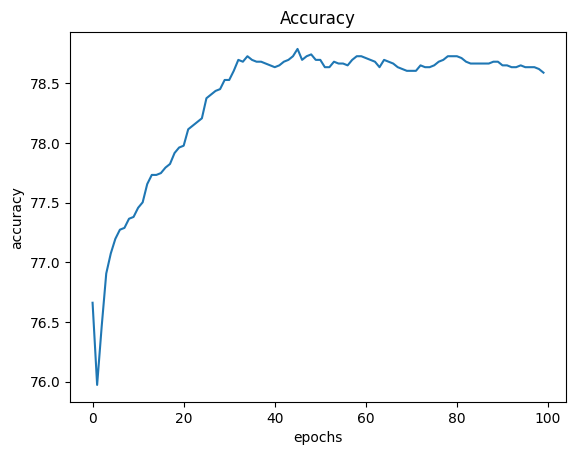

In [21]:
import matplotlib.pyplot as plt

# x axis values 
x = range(100)
# corresponding y axis values 
y = accuracy
    
# plotting the points  
plt.plot(x, y) 
    
# naming the x axis 
plt.xlabel('epochs') 
# naming the y axis 
plt.ylabel('accuracy') 
    
# giving a title to my graph 
plt.title('Accuracy') 
    
# function to show the plot 
plt.show() 

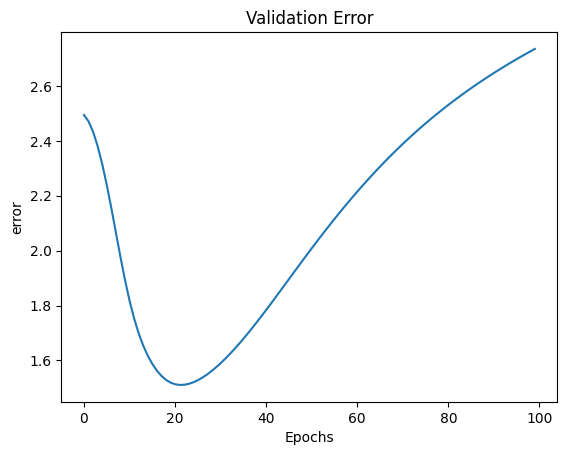

In [22]:
# x axis values 
x = range(100)
# corresponding y axis values 
y = val_errors
    
# plotting the points  
plt.plot(x, y) 
    
# naming the x axis 
plt.xlabel('Epochs') 
# naming the y axis 
plt.ylabel('error') 
    
# giving a title to my graph 
plt.title('Validation Error') 
    
# function to show the plot 
plt.show() 

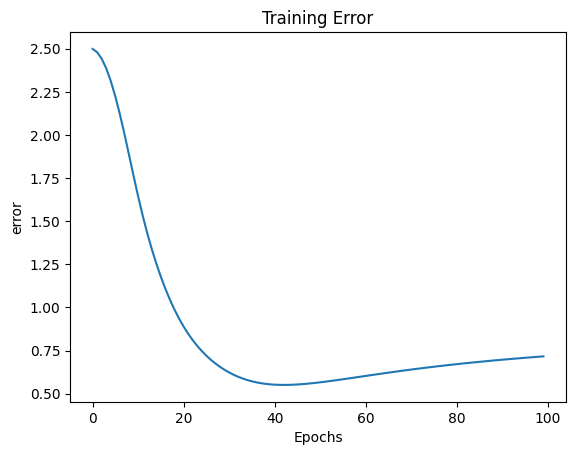

In [25]:
# x axis values 
x = range(100)
# corresponding y axis values 
y = train_errors
    
# plotting the points  
plt.plot(x, y) 
    
# naming the x axis 
plt.xlabel('Epochs') 
# naming the y axis 
plt.ylabel('error') 
    
# giving a title to my graph 
plt.title('Training Error') 
    
# function to show the plot 
plt.show()

In [26]:
import pickle

with open('vit_adam_2layer_weights.pkl', 'wb') as fp:
    pickle.dump(mlp.weights, fp)
    print('weights saved successfully to file')

with open('vit_adam_2layer_bias.pkl', 'wb') as fp:
    pickle.dump(mlp.bias, fp)
    print('bias saved successfully to file')

weights saved successfully to file
bias saved successfully to file


In [28]:
data = {}
data['test']  = dict(np.load('dataverse_files/Dataset5_raw_test.npz'))
data['test']['image'] = (data['test']['image'] - mean) / devia
conf_matrix = np.zeros(shape=(5, 5))
transform = transforms.Compose([transforms.ToTensor()])
print(data['test']['image'].transpose(0, 3, 1, 2).shape)
testset = CustomDataset(data['test']['image'], data['test']['image_label'], transform)
test_loader = DataLoader(testset, 64, shuffle=True)


y_pred = []
y_train = []
for x, y in test_loader:
    y_pred = y_pred + model(torch.tensor(x).to(device)).cpu().detach().numpy().tolist()
    y_train = y_train + y.detach().numpy().tolist()
    
print(len(y_pred))
print(len(y_train))

y_true = np.zeros(shape=(len(y_train), 5))

for i in range(len(y_train)):
    y_true[i, y_train[i]] = 1

y_net = np.reshape(np.array(y_pred),(-1,100))

test_error = 0
correct_count = 0

for j in range(len(y_train)):
    out = mlp.forward_pass(y_net[j:j+1,])
    test_error += cross_entropy_loss(out, y_true[j:j+1,])
    # count correct
    correct = np.argmax(out, axis=1)
    conf_matrix[correct, y_train[j]] += 1
    if correct[0] == y_train[j]:
        correct_count += 1

test_error = test_error / len(y_train)

print('Correct Predictions %(TEST) = ', 100*correct_count/len(y_train))
print('Error (Train) = ', test_error)
print(conf_matrix)

(6540, 3, 224, 224)


<ipython-input-28-0cd8582168a3>:14: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = y_pred + model(torch.tensor(x).to(device)).cpu().detach().numpy().tolist()


6540
6540
Correct Predictions %(TEST) =  78.01223241590215
Error (Train) =  2.75404848300141
[[ 560.   42.   42.   86.   60.]
 [  26.  878.  147.   35.   17.]
 [  55.  214. 1675.   48.  160.]
 [ 100.   50.   47. 1284.   38.]
 [  97.   19.  128.   27.  705.]]


<Axes: >

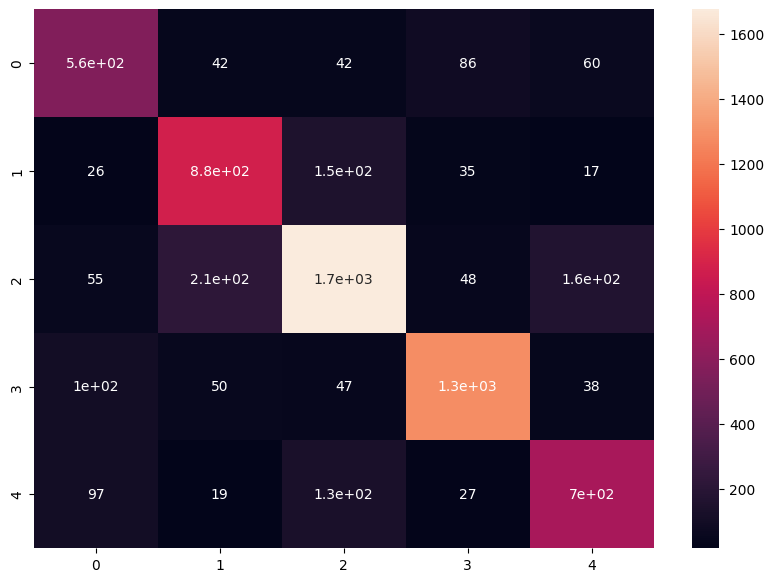

In [29]:
import seaborn as sn
import pandas as pd
import matplotlib.pyplot as plt

plt.figure(figsize = (10,7))
sn.heatmap(conf_matrix, annot=True)

In [35]:
def cross_entropy_loss(AL, Y):
    m = Y.shape[0]
    cost = -1 * np.sum(np.multiply( np.log(AL), Y) + np.multiply( np.log(1 - AL), 1 - Y)) / m
    cost = np.squeeze(cost)

    return cost

y_net = np.reshape(np.array(y_pred),(-1,100))
y_net_val = np.array(y_pred_val).reshape(-1,100)
### normalize the outputs from the feature extractor

mlp   = FCN([100, 40, 5], None, 0.000000001, 0.9, None, 0, 0)

accuracy = []
val_errors = []
train_errors = []
max = 0
## training loop
batch_size = 1
iterations = int(y_net.shape[0] / batch_size)
val_iter   = y_net_val.shape[0]

for i in range(100):
    print('Epoch:' + str(i+1))
    train_error = 0
    val_error = 0
    val_correct = 0

    # batch size = 16
    for j in range(iterations):
        out = mlp.forward_pass(y_net[j*batch_size: j*batch_size+batch_size,])
        #print(out)
        train_error += cross_entropy_loss(out, y_true[j*batch_size: j*batch_size+batch_size,])
        err = (y_true[j*batch_size:j*batch_size+batch_size] - out) / batch_size
        #print(err)
        
        mlp.back_pass(err)
        mlp.update_weights()

    for j in range(val_iter):
        out = mlp.forward_pass(y_net_val[j:j+1,])
        val_error += cross_entropy_loss(out, y_true_val[j:j+1,])
        # count correct
        correct = np.argmax(out, axis=1)

        if correct[0] == y_val[j]:
            val_correct += 1
    
    val_error = val_error / val_iter
    train_error = train_error / iterations

    train_errors.append(train_error)
    val_errors.append(val_error)
    accuracy.append(100*val_correct/val_iter)
    
    if np.isnan(train_error) or np.isnan(val_error):
        break

    if accuracy[-1] > max:
        max = accuracy[-1]
        mlp.cache_bestweights()

    print('Correct Predictions %(VAL) = ', accuracy[-1])    
    print('Error (VAL) = ', val_error)
    print('Error (Train) = ', train_error)

Epoch:1


<ipython-input-16-63faea024d4a>:8: RuntimeWarning: overflow encountered in exp
  return np.exp(Z) / np.sum(np.exp(Z), axis = 1, keepdims=True)
<ipython-input-16-63faea024d4a>:8: RuntimeWarning: invalid value encountered in true_divide
  return np.exp(Z) / np.sum(np.exp(Z), axis = 1, keepdims=True)
<ipython-input-35-045cb0daa116>:3: RuntimeWarning: divide by zero encountered in log
  cost = -1 * np.sum(np.multiply( np.log(AL), Y) + np.multiply( np.log(1 - AL), 1 - Y)) / m
<ipython-input-35-045cb0daa116>:3: RuntimeWarning: invalid value encountered in multiply
  cost = -1 * np.sum(np.multiply( np.log(AL), Y) + np.multiply( np.log(1 - AL), 1 - Y)) / m
